# Ejercicio 2 — Simulación de un único rayo binario

**Etiqueta de uso de IA:** *Sin IA*.

En el **modelo binario** un rayo discreto queda determinado por una dirección entera
$(\alpha,\beta)$ y un desplazamiento entero $s$: el rayo selecciona los píxeles cuyo
**centro** $(i,j)$ satisface

$$\alpha\, i + \beta\, j = s .$$

Es la versión discreta de la ecuación continua $n_\theta^{T} p = s$ que define la recta
$\ell_{\theta,s}$, pero acá no se calcula la intersección geométrica de la recta con cada
píxel: el píxel entra o no entra, sin peso. La medición asociada es entonces simplemente la
suma de las atenuaciones de los píxeles seleccionados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "image.cmap": "gray"})


def guardar(fig, nombre):
    # Guarda la figura en figuras/, como pide el formato de entrega.
    fig.savefig(os.path.join("figuras", nombre + ".png"), bbox_inches="tight", dpi=150)


X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8
x_fantoma = X_fantoma.reshape(-1)   # k = i*n + j


## a) `mascara_rayo(n, direccion, s)`

Devuelve $M_r \in \{0,1\}^{n\times n}$ con un $1$ en los píxeles seleccionados por el rayo
$r$ y $0$ en el resto. La implementación es vectorizada: armamos la matriz de valores
$\alpha i + \beta j$ por *broadcasting* y la comparamos contra $s$.

In [2]:
def mascara_rayo(n, direccion, s):
    # M[i,j] = 1  <=>  alpha*i + beta*j == s  (el centro del píxel está sobre el rayo)
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)   # varía con la fila
    j = np.arange(n).reshape(1, n)   # varía con la columna
    return (alpha * i + beta * j == s).astype(float)


# Chequeo contra el ejemplo de la Figura 6 del enunciado (n = 4).
M_r1 = mascara_rayo(4, (1, 1), 3)    # i + j = 3
M_r2 = mascara_rayo(4, (2, 1), 4)    # 2i + j = 4

print("r1:  i + j = 3")
print(M_r1.astype(int))
print("vectorizada:", M_r1.reshape(-1).astype(int))
print()
print("r2:  2i + j = 4")
print(M_r2.astype(int))
print("vectorizada:", M_r2.reshape(-1).astype(int))

r1:  i + j = 3
[[0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]
 [1 0 0 0]]
vectorizada: [0 0 0 1 0 0 1 0 0 1 0 0 1 0 0 0]

r2:  2i + j = 4
[[0 0 0 0]
 [0 0 1 0]
 [1 0 0 0]
 [0 0 0 0]]
vectorizada: [0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0]


Las filas vectorizadas coinciden exactamente con las de la Figura 6 del enunciado:
$a_{r_1}^T = [0001\,|\,0010\,|\,0100\,|\,1000]$ y
$a_{r_2}^T = [0000\,|\,0010\,|\,1000\,|\,0000]$.

Obsérvese que $r_2$ selecciona sólo $2$ píxeles aunque la recta geométrica de referencia
atraviesa más: los píxeles cuyo centro no satisface la ecuación quedan afuera. Ésa es
precisamente la limitación del modelo binario, que recién se corrige usando longitudes de
intersección.

## b) Máscaras para cinco direcciones

Visualizamos las máscaras para
$(\alpha,\beta) \in \{(1,0),\,(0,1),\,(1,1),\,(1,-1),\,(2,1)\}$
con los desplazamientos $s = 3,\,5,\,7,\,0,\,8$ respectivamente.

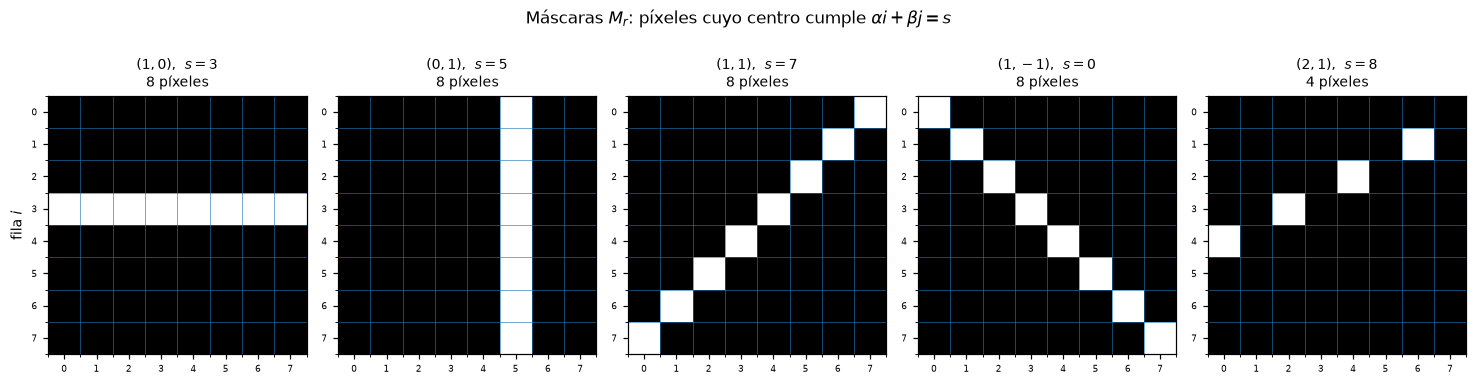

In [3]:
casos = [((1, 0), 3), ((0, 1), 5), ((1, 1), 7), ((1, -1), 0), ((2, 1), 8)]
mascaras = [mascara_rayo(n, d, s) for d, s in casos]

fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.2))
for ax, M, (d, s) in zip(axes, mascaras, casos):
    ax.imshow(M, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"$({d[0]},{d[1]})$,  $s={s}$\n{int(M.sum())} píxeles", fontsize=9)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.tick_params(labelsize=6)
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="tab:blue", lw=0.4)
axes[0].set_ylabel("fila $i$")
fig.suptitle(r"Máscaras $M_r$: píxeles cuyo centro cumple $\alpha i + \beta j = s$", y=1.06)
fig.tight_layout()
guardar(fig, "ejercicio_02b_mascaras")
plt.show()

Se ve con claridad el rol de cada dirección:

- $(1,0)$ con $s=3$ da la ecuación $i = 3$: una **fila** completa.
- $(0,1)$ con $s=5$ da $j = 5$: una **columna** completa.
- $(1,1)$ con $s=7$ da $i+j=7$: la **antidiagonal** principal.
- $(1,-1)$ con $s=0$ da $i=j$: la **diagonal** principal.
- $(2,1)$ con $s=8$ da $2i+j=8$: una recta más inclinada que sólo pasa por $4$ centros,
  porque al avanzar una fila hay que retroceder dos columnas y muchos centros caen fuera de
  la grilla.

Nótese que la cantidad de píxeles por rayo **no** es constante: las direcciones "sencillas"
recogen $8$ píxeles, mientras que las inclinadas recogen bastante menos. Esto ya anticipa
que las direcciones $(2,1)$, $(1,2)$, $(3,1)$ aportan muchas ecuaciones, pero cada una con
poca información.

## c) Mediciones $b_r = \sum_{i,j} (M_r)_{ij}\,(X_{\text{fantoma}})_{ij}$

La medición de un rayo binario es el producto componente a componente (producto de
Hadamard) entre la máscara y el fantoma, sumado. Equivalentemente es el producto interno
$a_r^{T} x$ entre la máscara vectorizada y la imagen vectorizada; calculamos las dos formas
y verificamos que coinciden.

In [4]:
print(f"{'dirección':>12} {'s':>4} {'#píxeles':>9} {'b_r (M∘X)':>12} {'b_r (a_r·x)':>13}")
print("-" * 55)
b_valores = []
for M, (d, s) in zip(mascaras, casos):
    b_hadamard = float((M * X_fantoma).sum())
    b_interno = float(M.reshape(-1) @ x_fantoma)
    b_valores.append(b_hadamard)
    print(f"{str(d):>12} {s:>4} {int(M.sum()):>9} {b_hadamard:>12.4f} {b_interno:>13.4f}")

print()
print("¿coinciden ambas formas?",
      np.allclose([float((M * X_fantoma).sum()) for M in mascaras],
                  [float(M.reshape(-1) @ x_fantoma) for M in mascaras]))

   dirección    s  #píxeles    b_r (M∘X)   b_r (a_r·x)
-------------------------------------------------------
      (1, 0)    3         8       2.3000        2.3000
      (0, 1)    5         8       2.4000        2.4000
      (1, 1)    7         8       1.2000        1.2000
     (1, -1)    0         8       1.9000        1.9000
      (2, 1)    8         4       1.1000        1.1000

¿coinciden ambas formas? True


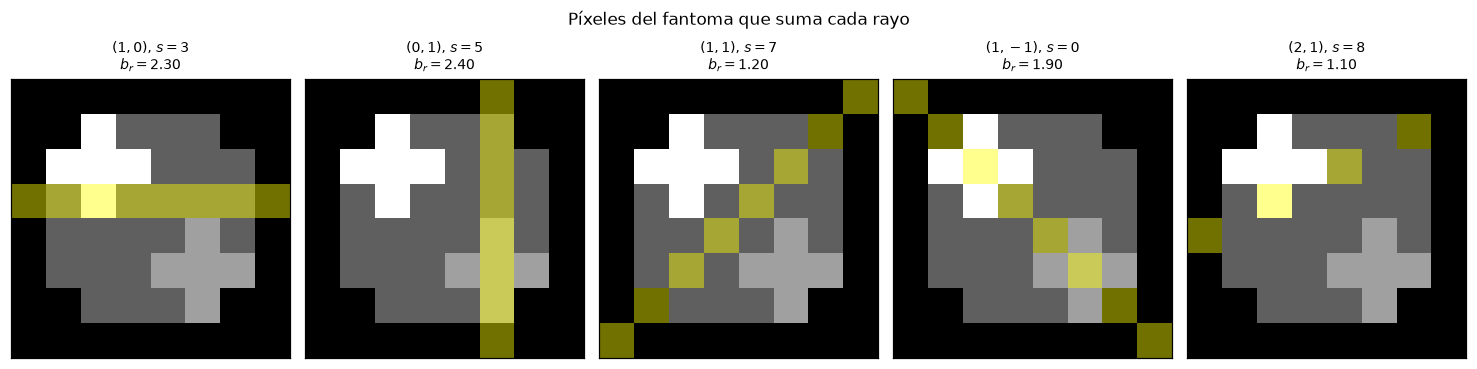

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.2))
for ax, M, (d, s), b in zip(axes, mascaras, casos, b_valores):
    ax.imshow(X_fantoma, cmap="gray", vmin=0, vmax=X_fantoma.max())
    # Resaltamos en rojo los píxeles que el rayo suma.
    ax.imshow(np.ma.masked_where(M == 0, M), cmap="autumn", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(f"$({d[0]},{d[1]})$, $s={s}$\n$b_r = {b:.2f}$", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Píxeles del fantoma que suma cada rayo", y=1.04)
fig.tight_layout()
guardar(fig, "ejercicio_02c_mediciones")
plt.show()

## d) ¿Por qué dos rayos con orientaciones diferentes pueden dar la misma medición?

Porque la medición **no es el conjunto de píxeles**, sino un único número: la suma de sus
atenuaciones. Formalmente $b_r = a_r^{T}x$ es la imagen de $x$ por el funcional lineal
$a_r^{T}:\mathbb{R}^{64}\to\mathbb{R}$, y una función que va de $\mathbb{R}^{64}$ a
$\mathbb{R}$ colapsa muchísima información. Dos funcionales distintos
$a_r^{T} \neq a_{r'}^{T}$ dan el mismo valor sobre un $x$ particular cuando

$$(a_r - a_{r'})^{T}\,x = 0,$$

es decir cuando la **diferencia** de las máscaras es ortogonal a la imagen. Esto ocurre por
dos motivos concretos, ambos presentes en nuestro fantoma:

1. **Compensación de valores.** Los rayos pueden tocar píxeles distintos cuyas atenuaciones
   sumen lo mismo. Cualquier redistribución de la "masa" que conserve la suma sobre la
   máscara es indistinguible para ese rayo.
2. **Píxeles nulos.** Todo el borde del fantoma vale $0$. Dos rayos que coincidan en los
   píxeles no nulos y difieran sólo en píxeles de valor $0$ dan **exactamente** la misma
   medición.

Lo comprobamos numéricamente barriendo todos los rayos de varias direcciones y buscando
colisiones en el valor de $b_r$.

In [6]:
from collections import defaultdict

todos = []
for d in [(1, 0), (0, 1), (1, 1), (1, -1), (2, 1)]:
    a, be = d
    valores_s = np.unique(a * np.arange(n).reshape(n, 1) + be * np.arange(n).reshape(1, n))
    for s in valores_s:
        M = mascara_rayo(n, d, int(s))
        todos.append((d, int(s), M, float((M * X_fantoma).sum())))

grupos = defaultdict(list)
for d, s, M, b in todos:
    grupos[round(b, 10)].append((d, s))

print(f"Se generaron {len(todos)} rayos y sólo {len(grupos)} valores distintos de b_r.\n")
print("Ejemplos de rayos con ORIENTACIONES DISTINTAS y la MISMA medición:\n")
mostrados = 0
for b, lista in sorted(grupos.items(), reverse=True):
    direcciones_distintas = {d for d, s in lista}
    if len(direcciones_distintas) > 1 and mostrados < 5:
        etiquetas = ",  ".join(f"({d[0]},{d[1]})|s={s}" for d, s in lista)
        print(f"  b_r = {b:5.2f}   ->   {etiquetas}")
        mostrados += 1

Se generaron 68 rayos y sólo 19 valores distintos de b_r.

Ejemplos de rayos con ORIENTACIONES DISTINTAS y la MISMA medición:

  b_r =  3.30   ->   (1,0)|s=2,  (0,1)|s=2
  b_r =  2.40   ->   (1,0)|s=5,  (0,1)|s=5
  b_r =  2.30   ->   (1,0)|s=3,  (0,1)|s=3
  b_r =  2.00   ->   (1,0)|s=4,  (0,1)|s=4
  b_r =  1.70   ->   (1,0)|s=1,  (0,1)|s=1


rayo A: dirección (1, 0), s=1  ->  b = 1.70
rayo B: dirección (0, 1), s=6  ->  b = 1.40
¿máscaras iguales? False
(a_A - a_B)^T x  = 0.30000000000000004


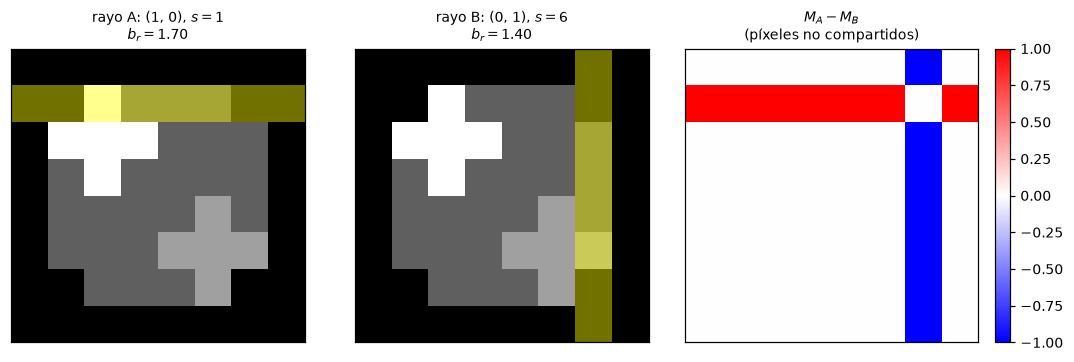

In [7]:
# Un par concreto: misma medición, píxeles distintos.
d1, s1 = (1, 0), 1
d2, s2 = (0, 1), 6
M1, M2 = mascara_rayo(n, d1, s1), mascara_rayo(n, d2, s2)
b1, b2 = float((M1 * X_fantoma).sum()), float((M2 * X_fantoma).sum())

print(f"rayo A: dirección {d1}, s={s1}  ->  b = {b1:.2f}")
print(f"rayo B: dirección {d2}, s={s2}  ->  b = {b2:.2f}")
print("¿máscaras iguales?", np.array_equal(M1, M2))
print("(a_A - a_B)^T x  =", float((M1 - M2).reshape(-1) @ x_fantoma))

fig, axes = plt.subplots(1, 3, figsize=(10.0, 3.2))
for ax, M, t in zip(axes[:2], [M1, M2],
                    [f"rayo A: {d1}, $s={s1}$", f"rayo B: {d2}, $s={s2}$"]):
    ax.imshow(X_fantoma, cmap="gray", vmin=0, vmax=X_fantoma.max())
    ax.imshow(np.ma.masked_where(M == 0, M), cmap="autumn", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(t + f"\n$b_r = {float((M * X_fantoma).sum()):.2f}$", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
im = axes[2].imshow(M1 - M2, cmap="bwr", vmin=-1, vmax=1)
axes[2].set_title("$M_A - M_B$\n(píxeles no compartidos)", fontsize=9)
axes[2].set_xticks([])
axes[2].set_yticks([])
fig.colorbar(im, ax=axes[2], fraction=0.046)
fig.tight_layout()
guardar(fig, "ejercicio_02d_ambiguedad")
plt.show()

### Consecuencia para la reconstrucción

Esta ambigüedad no es una curiosidad aislada: es el germen del problema que estudiamos en el
Ejercicio 4. Si $(a_r - a_{r'})^{T}x = 0$, la dirección $a_r - a_{r'}$ es "invisible" para
ese par de rayos. En general, cualquier vector $v \neq 0$ con $Av = 0$ produce dos imágenes
distintas $x$ y $x + v$ con **idénticas mediciones**, y ninguna cantidad de álgebra puede
distinguirlas. Medir más rayos, y sobre todo desde más orientaciones, es la manera de
achicar ese espacio nulo.